In [47]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  # 다항특성 자동생성, # 정규화클래스
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax # expit는 이진분류함수, softmax는 다중분류함수 => 0~1사이의 숫자로 변환시키는 기능

In [48]:
# logistiRegression 이진분류 -> 다중분류

In [49]:
fish = pd.read_csv('data/fish_logistic.csv')
fish.head(2)

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.0200
1,Bream,290.0,26.3,31.2,12.48,4.3056


In [50]:
fish['Species'].unique() # 종속변수의 범주 갯수 파악 -> 7개

<StringArray>
['Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt']
Length: 7, dtype: str

In [51]:
data = fish[fish.columns[1:]].values
label = fish['Species'].values

In [52]:
# 데이터 분리
train_data, test_data, train_label, test_label = \
train_test_split(data,label,random_state=42)

In [53]:
# logisticRegression - 정규화작업을 해야 함
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [54]:
# 다중분류
# C(대문자표기) - alpha, C(규제의미: 숫자가 높아질수록 완화, 낮아질수록 강화)
# alpha for 문 그래프로 가장 최적화된 규제를 찾아 적용
# max_iter 반복을 자동화해주는 매개변수
train_score = []
test_score = []
cc = [0.001,0.01,0.1,1,10,20,50,100]
for c in cc:
    lr = LogisticRegression(C=c, max_iter=1000)
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled,train_label))
    test_score.append(lr.score(test_scaled,test_label))
    print()

In [55]:
# 다중분류
# C(대문자표기) - alpha,C 규제 : 높아지면 완화, 낮아지면 강화
# alpha for문 그래프로 가장 최적화된 규제를 찾아서 적용 
# max_iter 반복을 자동화해주는 매개변수
train_score = []
test_score = []
cc = [0.001,0.01,0.1,1,10,20,50,100]
for c in cc: 
    lr = LogisticRegression(C=c,max_iter=1000)
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled,train_label))
    test_score.append(lr.score(test_scaled,test_label))

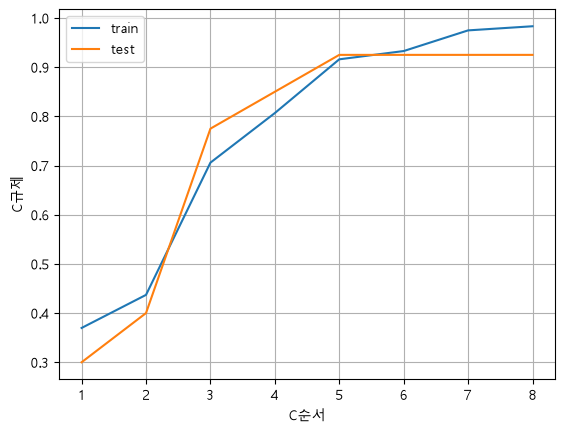

In [56]:
# C의 규제 선그래프
list1 = [1,2,3,4,5,6,7,8]
plt.plot(list1,train_score)
plt.plot(list1,test_score)
plt.xlabel('C순서')
plt.ylabel('C규제')
plt.legend(['train','test'])
plt.grid()
plt.show()

In [57]:
lr.classes_

array(['Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish'],
      dtype=object)

In [58]:
lr.predict_proba(test_scaled[:5])
decisions = lr.decision_function(test_scaled[:5])
from scipy.special import softmax
soft1 = softmax(decisions,axis=1)  #axis =1:행방향 / axis=0:열방향
np.round(soft1,decimals=3)

array([[0.   , 0.002, 0.964, 0.   , 0.032, 0.001, 0.001],
       [0.   , 0.   , 0.012, 0.   , 0.001, 0.986, 0.   ],
       [0.   , 0.   , 0.005, 0.805, 0.001, 0.189, 0.   ],
       [0.001, 0.025, 0.133, 0.001, 0.723, 0.   , 0.116],
       [0.   , 0.   , 0.971, 0.   , 0.027, 0.001, 0.   ]])

In [59]:
print('train 정확도: ', lr.score(train_scaled,train_label))
print('test 정확도: ', lr.score(test_scaled,test_label))

train 정확도:  0.9831932773109243
test 정확도:  0.925


In [60]:
fish[:1]

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.02


In [61]:
# 242.0 25.4 30.0 11.52 4.0200
# 290.0 26.3 31.2 12.48 4.3056
# 무게, 길이, 대각선, 높이, 넓이를 입력받아
# 분류생선과 확률을 출력하시오.
# 분류생선은 98.123%의 확률로 bream 판별됩니다. 

In [62]:
lr.classes_

array(['Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish'],
      dtype=object)

In [63]:
# in_data= input('무게, 길이,대각선, 높이, 넓이를 입력하세요>> 예)242.0,25.4,30.0,11.52,4.0200')
# in_data = '242.0,25.4,30.0,11.52,4.0200'
# in_data = '55,14.7,16.5,6.8475,2.3265'
in_data = '32,13.7,14.7,3.528,1.9992' 
# in_data = '300,35,38.8,5.9364,4.3844' 
in_data = in_data.split(',')
in_data = list(map(float,in_data))

# 정규화
in_data_scaled = ss.transform([in_data])

# 예측 - 'Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish'
result = lr.predict(in_data_scaled)
result2 = lr.predict_proba(in_data_scaled)
if result[0] == 'Bream':
    result3 = result2[0][0]
elif result[0] == 'Parkki':
    result3 = result2[0][1]
elif result[0] == 'Perch':
    result3 = result2[0][2]
elif result[0] == 'Pike':
    result3 = result2[0][3]
elif result[0] == 'Roach':
    result3 = result2[0][4]
elif result[0] == 'Smelt':
    result3 = result2[0][5]
elif result[0] == 'Whitefish':
    result3 = result2[0][6]
print("test : ",result3)
# 분류 생선 : 93.1%의 확률로 Bream 판별됩니다.
print(f"분류 생선 : {result3*100:.2f}%의 확률로 {result[0]}  판별됩니다.")

test :  0.6587335396330459
분류 생선 : 65.87%의 확률로 Perch  판별됩니다.
